# Alinhar Ground Truth (Gemini) com Bounding Box Local

Alinha o gabarito gerado pelo Gemini (texto + contexto, sem coordenadas — ver `notebooks/01.gerar_ground_truth_gemini.ipynb`) com a extração local do documento (tokens com bounding box, vindos de PyMuPDF ou OCR — `notebooks/02.extrair_texto_ocr_local.ipynb`), produzindo um gabarito final com posição espacial (bbox) e offsets de texto, no mesmo referencial de coordenadas usado pelo pipeline local de detecção.

**Contrato de entrada esperado:**

1) JSON do Gemini (`data/documento_social/02.gabarito_gemini/<modelo>/`):
```json
{
  "document_id": "...",
  "entities": [
    {"type": "CPF", "text": "123.456.789-09", "page": 3,
     "occurrence_index": 1, "context_before": "...", "context_after": "...",
     "confidence": "high", "notes": ""}
  ]
}
```

2) JSON de extração local (`data/documento_social/03.extracao_ocr_local/`):
```json
{
  "document_id": "...",
  "pages": [
    {"page": 1, "tokens": [{"text": "João", "bbox": [0, 0, 0, 0]}]}
  ]
}
```

**Saída:** um JSON de gabarito alinhado por documento em `data/documento_social/04.gabarito_alinhado/<modelo>/` (com bbox e offsets), mais um relatório agregado de entidades não alinhadas, para revisão manual.

**Deduplicação de span físico:** às vezes o Gemini anota a mesma ocorrência física de PII duas vezes — por exemplo quando o documento tem uma marca d'água/carimbo de autenticação sobreposto exatamente sobre o texto original ("Marinely de Paula Bomfim" anotada 2x na mesma posição, uma delas com nota "(watermark)", achado originalmente no holdout em 2026-09-11 e replicado aqui). As duas entidades do Gemini alinham para o MESMO span físico de token (mesma página+tipo+char_start+char_end), o que é impossível de casar duas vezes na avaliação e penalizava artificialmente o recall medido nos notebooks consumidores (06.treinar_bertimbau.ipynb). Este notebook detecta esses grupos e marca todas as entidades do grupo exceto uma (a de maior `similarity_score`) como `unmatched`/`duplicata_span_fisico` — mesma correção já validada em `notebooks/09.alinhar_ground_truth_holdout.ipynb`.

**Pré-requisitos:** `pip install rapidfuzz` (no venv GERAL do projeto, `.venv` — não no `.venv_ocr`)

In [1]:
import json
import re
import unicodedata
from pathlib import Path

from rapidfuzz import fuzz

## Configuração

`MODELO_GABARITO` escolhe qual subpasta de `gabarito_gemini/` usar como entrada (ver `notebooks/gerar_ground_truth_gemini.ipynb` — uma subpasta por modelo). Os limiares de similaridade abaixo foram um ponto de partida (não calibrados ainda contra extração real) — ver `anotacoes/anotacoes.txt` para o racional e recalibrar se a taxa de alinhamento automático vier baixa.

In [2]:
def encontrar_raiz_projeto(marcador: str = "requirements.txt") -> Path:
    p = Path.cwd()
    for _ in range(6):
        if (p / marcador).exists():
            return p
        p = p.parent
    raise RuntimeError(f"Não encontrei a raiz do projeto ({marcador}) subindo a partir de {Path.cwd()}")

RAIZ = encontrar_raiz_projeto()

MODELO_GABARITO = "gemini-2.5-flash"  # subpasta em data/documento_social/02.gabarito_gemini/

PASTA_GROUND_TRUTH = RAIZ / "data" / "documento_social" / "02.gabarito_gemini" / MODELO_GABARITO
PASTA_EXTRACAO = RAIZ / "data" / "documento_social" / "03.extracao_ocr_local"
PASTA_SAIDA = RAIZ / "data" / "documento_social" / "04.gabarito_alinhado" / MODELO_GABARITO

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

LIMIAR_SIMILARIDADE_TEXTO = 80    # 0-100, usado para NOME/ENDERECO (fuzzy sobre texto normalizado)
LIMIAR_SIMILARIDADE_DIGITOS = 85  # 0-100, usado para CPF/RG (fuzzy sobre dígitos; CIN entra como CPF)
JANELA_CONTEXTO_CHARS = 80        # quantos caracteres ao redor considerar para desambiguar por contexto

print(f"Raiz do projeto:  {RAIZ}")
print(f"Ground truth:      {PASTA_GROUND_TRUTH}")
print(f"Extração local:    {PASTA_EXTRACAO}")
print(f"Saída:             {PASTA_SAIDA}")

Raiz do projeto:  d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3
Ground truth:      d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\02.gabarito_gemini\gemini-2.5-flash
Extração local:    d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\03.extracao_ocr_local
Saída:             d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\04.gabarito_alinhado\gemini-2.5-flash


## Funções de normalização e indexação de página

In [3]:
def normalizar_texto(s: str) -> str:
    """minúsculas, sem acento, espaços colapsados — para comparação de NOME/ENDERECO."""
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode("ascii")
    s = s.lower()
    s = re.sub(r"\s+", " ", s).strip()
    return s


def somente_digitos(s: str) -> str:
    return re.sub(r"\D", "", s)


def construir_indices_pagina(tokens: list) -> dict:
    """Concatena os tokens da página em texto corrido e mapeia offsets -> índice do token,
    tanto para o texto normalizado quanto para a projeção somente-dígitos."""
    texto_partes = []
    digitos_partes = []
    # mapa_texto[i] = indice do token cujo caractere ocupa a posição i do texto normalizado
    mapa_texto = []
    mapa_digitos = []

    for idx, tok in enumerate(tokens):
        txt_norm = normalizar_texto(tok["text"])
        if txt_norm:
            if texto_partes:
                texto_partes.append(" ")
                mapa_texto.append(idx)  # espaço separador associado ao token seguinte
            texto_partes.append(txt_norm)
            mapa_texto.extend([idx] * len(txt_norm))

        digs = somente_digitos(tok["text"])
        if digs:
            digitos_partes.append(digs)
            mapa_digitos.extend([idx] * len(digs))

    return {
        "texto": "".join(texto_partes),
        "mapa_texto": mapa_texto,
        "digitos": "".join(digitos_partes),
        "mapa_digitos": mapa_digitos,
        "tokens": tokens,
    }

## Busca fuzzy e desambiguação de candidatos

In [4]:
def buscar_candidatos_fuzzy(padrao: str, alvo: str, limiar: int, max_candidatos: int = 5) -> list:
    """Retorna até max_candidatos melhores alinhamentos aproximados de `padrao` dentro de `alvo`.

    Estratégia: janela deslizante grosseira usando partial_ratio_alignment repetidamente,
    removendo a região já encontrada a cada rodada, para permitir múltiplas ocorrências.
    """
    if not padrao or not alvo:
        return []

    candidatos = []
    alvo_restante = alvo
    offset_acumulado = 0

    for _ in range(max_candidatos):
        alinhamento = fuzz.partial_ratio_alignment(padrao, alvo_restante)
        if alinhamento is None or alinhamento.score < limiar:
            break

        inicio = offset_acumulado + alinhamento.dest_start
        fim = offset_acumulado + alinhamento.dest_end
        candidatos.append({"start": inicio, "end": fim, "score": alinhamento.score})

        # mascara a região encontrada para permitir achar a próxima ocorrência
        nova_alvo = (
            alvo_restante[: alinhamento.dest_start]
            + ("#" * (alinhamento.dest_end - alinhamento.dest_start))
            + alvo_restante[alinhamento.dest_end :]
        )
        alvo_restante = nova_alvo

    candidatos.sort(key=lambda c: c["start"])
    return candidatos


def escolher_melhor_candidato(candidatos: list, entidade: dict, alvo_texto: str):
    """Desempata candidatos usando contexto (before/after) e occurrence_index."""
    if not candidatos:
        return None
    if len(candidatos) == 1:
        return candidatos[0]

    ctx_before = normalizar_texto(entidade.get("context_before", ""))
    ctx_after = normalizar_texto(entidade.get("context_after", ""))

    pontuados = []
    for c in candidatos:
        janela_antes = alvo_texto[max(0, c["start"] - JANELA_CONTEXTO_CHARS) : c["start"]]
        janela_depois = alvo_texto[c["end"] : c["end"] + JANELA_CONTEXTO_CHARS]
        score_ctx = 0
        if ctx_before:
            score_ctx += fuzz.partial_ratio(ctx_before, janela_antes)
        if ctx_after:
            score_ctx += fuzz.partial_ratio(ctx_after, janela_depois)
        pontuados.append((score_ctx, c))

    pontuados.sort(key=lambda x: x[0], reverse=True)

    idx_desejado = max(1, entidade.get("occurrence_index", 1)) - 1
    ordenados_por_posicao = sorted(candidatos, key=lambda c: c["start"])
    if idx_desejado < len(ordenados_por_posicao):
        candidato_por_indice = ordenados_por_posicao[idx_desejado]
        # se o candidato por occurrence_index também está entre os top-2 por contexto, prioriza ele
        top_por_contexto = {id(p[1]) for p in pontuados[:2]}
        if id(candidato_por_indice) in top_por_contexto:
            return candidato_por_indice

    return pontuados[0][1]

## Agrupamento de bbox por linha e alinhamento de uma entidade

In [5]:
def agrupar_bboxes_por_linha(tokens: list, indices: list) -> list:
    """Une os bboxes dos tokens cobertos, quebrando em uma caixa por linha
    (detecta mudança de linha por salto vertical do bbox)."""
    if not indices:
        return []

    grupos = []
    grupo_atual = [tokens[indices[0]]["bbox"]]
    y_ref = tokens[indices[0]]["bbox"][1]

    for i in indices[1:]:
        bbox = tokens[i]["bbox"]
        altura_ref = grupo_atual[-1][3] - grupo_atual[-1][1]
        if abs(bbox[1] - y_ref) > max(altura_ref * 0.6, 3):
            grupos.append(grupo_atual)
            grupo_atual = [bbox]
            y_ref = bbox[1]
        else:
            grupo_atual.append(bbox)

    grupos.append(grupo_atual)

    caixas = []
    for g in grupos:
        x0 = min(b[0] for b in g)
        y0 = min(b[1] for b in g)
        x1 = max(b[2] for b in g)
        y1 = max(b[3] for b in g)
        caixas.append([x0, y0, x1, y1])
    return caixas


def alinhar_entidade(entidade: dict, indices_pagina: dict) -> dict:
    tipo = entidade["type"]
    resultado = dict(entidade)

    if tipo in ("CPF", "RG"):  # CIN entra como CPF (decisão 2026-09-09, ver PRD.md seção 8)
        padrao = somente_digitos(entidade["text"])
        alvo = indices_pagina["digitos"]
        mapa = indices_pagina["mapa_digitos"]
        limiar = LIMIAR_SIMILARIDADE_DIGITOS
    else:  # NOME, ENDERECO (e qualquer outro tipo textual futuro)
        padrao = normalizar_texto(entidade["text"])
        alvo = indices_pagina["texto"]
        mapa = indices_pagina["mapa_texto"]
        limiar = LIMIAR_SIMILARIDADE_TEXTO

    if not padrao or not alvo:
        resultado.update({"match_type": "unmatched", "reason": "padrão ou texto de página vazio"})
        return resultado

    candidatos = buscar_candidatos_fuzzy(padrao, alvo, limiar)
    escolhido = escolher_melhor_candidato(candidatos, entidade, alvo)

    if escolhido is None:
        resultado.update({"match_type": "unmatched", "reason": "sem candidato acima do limiar"})
        return resultado

    indices_tokens = sorted(set(mapa[escolhido["start"] : escolhido["end"]]))
    if not indices_tokens:
        resultado.update({"match_type": "unmatched", "reason": "span sem token correspondente"})
        return resultado

    bboxes = agrupar_bboxes_por_linha(indices_pagina["tokens"], indices_tokens)
    texto_extraido = " ".join(indices_pagina["tokens"][i]["text"] for i in indices_tokens)

    resultado.update({
        "match_type": "exact" if escolhido["score"] >= 99.9 else "fuzzy",
        "similarity_score": round(escolhido["score"], 1),
        "matched_text": texto_extraido,
        "char_start": escolhido["start"],
        "char_end": escolhido["end"],
        "bbox": bboxes,
    })
    return resultado

## Alinhamento de um documento completo

In [6]:
def deduplicar_span_fisico(entidades_alinhadas: list) -> int:
    """Duas entidades do gabarito Gemini podem alinhar para o MESMO span físico de token
    (mesma página+tipo+char_start+char_end) -- visto no holdout com "Marinely de Paula Bomfim"
    anotada 2x na mesma posição, uma delas com nota "(watermark)": o documento tem uma marca
    d'água/carimbo de autenticação sobreposto exatamente sobre o texto original, e o Gemini conta
    a mesma ocorrência física duas vezes. Como só existe UM span de token ali, é impossível casar
    as duas na avaliação -- métricas ficam artificialmente penalizadas (ver anotacoes.txt
    2026-09-11). Mesma correção já aplicada em notebooks/09.alinhar_ground_truth_holdout.ipynb,
    replicada aqui para o pipeline principal (treino/validação). Mantém a entidade de maior
    `similarity_score` de cada grupo duplicado e marca as demais como "unmatched" (mesmo bucket
    que outras falhas de alinhamento -- já ignorado pelos notebooks consumidores, incluindo o
    06.treinar_bertimbau.ipynb). Retorna quantas entidades foram desmarcadas.
    """
    grupos = {}
    for e in entidades_alinhadas:
        if e.get("match_type") == "unmatched":
            continue
        chave = (e["page"], e["type"], e.get("char_start"), e.get("char_end"))
        grupos.setdefault(chave, []).append(e)

    n_removidas = 0
    for membros in grupos.values():
        if len(membros) <= 1:
            continue
        membros_ordenados = sorted(membros, key=lambda e: -(e.get("similarity_score") or 0))
        for duplicata in membros_ordenados[1:]:
            duplicata["match_type"] = "unmatched"
            duplicata["reason"] = (
                "duplicata_span_fisico -- mesma posição de outra entidade do gabarito nesta "
                "página (provável dupla anotação de uma marca d'água/carimbo sobre o texto "
                "original); mantida a de maior similarity_score"
            )
            n_removidas += 1
    return n_removidas


def alinhar_documento(gabarito: dict, extracao: dict):
    paginas = {p["page"]: construir_indices_pagina(p["tokens"]) for p in extracao["pages"]}

    entidades_alinhadas = []

    for entidade in gabarito["entities"]:
        pagina_idx = paginas.get(entidade["page"])
        if pagina_idx is None:
            e = dict(entidade)
            e.update({"match_type": "unmatched", "reason": f"página {entidade['page']} não existe na extração"})
            entidades_alinhadas.append(e)
            continue

        alinhada = alinhar_entidade(entidade, pagina_idx)
        entidades_alinhadas.append(alinhada)

    n_duplicatas = deduplicar_span_fisico(entidades_alinhadas)

    nao_alinhadas = [e for e in entidades_alinhadas if e.get("match_type") == "unmatched"]

    resultado = dict(gabarito)
    resultado["entities"] = entidades_alinhadas
    return resultado, nao_alinhadas, n_duplicatas

## Loop principal — processa todos os gabaritos da pasta configurada

In [7]:
arquivos_gt = sorted(PASTA_GROUND_TRUTH.glob("*.json"))
if not arquivos_gt:
    raise SystemExit(f"Nenhum JSON de ground truth encontrado em {PASTA_GROUND_TRUTH}")

total_entidades = 0
total_alinhadas = 0
total_duplicatas = 0
relatorio_nao_alinhadas = []

for arq_gt in arquivos_gt:
    arq_ext = PASTA_EXTRACAO / arq_gt.name
    if not arq_ext.exists():
        print(f"[AVISO] Sem extração local correspondente para {arq_gt.name}, pulando.")
        continue

    gabarito = json.loads(arq_gt.read_text(encoding="utf-8"))
    extracao = json.loads(arq_ext.read_text(encoding="utf-8"))

    resultado, nao_alinhadas, n_duplicatas = alinhar_documento(gabarito, extracao)

    destino = PASTA_SAIDA / arq_gt.name
    destino.write_text(json.dumps(resultado, ensure_ascii=False, indent=2), encoding="utf-8")

    n_total = len(resultado["entities"])
    n_ok = n_total - len(nao_alinhadas)
    total_entidades += n_total
    total_alinhadas += n_ok
    total_duplicatas += n_duplicatas
    for e in nao_alinhadas:
        e["document_id"] = gabarito.get("document_id", arq_gt.stem)
    relatorio_nao_alinhadas.extend(nao_alinhadas)

    sufixo_dup = f" ({n_duplicatas} duplicata(s) de span físico descartada(s))" if n_duplicatas else ""
    print(f"{arq_gt.name}: {n_ok}/{n_total} entidades alinhadas -> {destino.name}{sufixo_dup}")

if total_entidades:
    taxa = 100 * total_alinhadas / total_entidades
    print(f"\nTotal: {total_alinhadas}/{total_entidades} entidades alinhadas automaticamente ({taxa:.1f}%)")
if total_duplicatas:
    print(f"Dessas, {total_duplicatas} eram duplicata de span físico (mesma posição de outra entidade -- ver anotacoes.txt 2026-09-11) e foram descartadas antes de contar como alinhadas.")

if relatorio_nao_alinhadas:
    rel_path = PASTA_SAIDA / "_nao_alinhadas.json"
    rel_path.write_text(json.dumps(relatorio_nao_alinhadas, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"{len(relatorio_nao_alinhadas)} entidade(s) não alinhada(s) -> revisar manualmente em {rel_path.name}")

clpif4a2h00b92pqd67v27lm9-ALTERAÇÃO 1º DA EMPRESA TL TRANSPOSTES E LOGISTICA LTDA ME.pdf.json: 47/48 entidades alinhadas -> clpif4a2h00b92pqd67v27lm9-ALTERAÇÃO 1º DA EMPRESA TL TRANSPOSTES E LOGISTICA LTDA ME.pdf.json (1 duplicata(s) de span físico descartada(s))
clpif4mn700bb2pqde5cy04ej-INSTRUMENTO PARTICULAR 1º ALTERAÇÃO CONTRATUAL.pdf.json: 69/71 entidades alinhadas -> clpif4mn700bb2pqde5cy04ej-INSTRUMENTO PARTICULAR 1º ALTERAÇÃO CONTRATUAL.pdf.json
clpif4v9800bd2pqd76oa1krz-INSTRUMENTO PARTICULAR 2º ALTERAÇÃO CONTRATUAL.pdf.json: 33/33 entidades alinhadas -> clpif4v9800bd2pqd76oa1krz-INSTRUMENTO PARTICULAR 2º ALTERAÇÃO CONTRATUAL.pdf.json
clpif50i000bf2pqd2ky17hb4-INSTRUMENTO PARTICULAR 4 ALTERAÇÃO CONTRATUAL 11082010.pdf.json: 16/17 entidades alinhadas -> clpif50i000bf2pqd2ky17hb4-INSTRUMENTO PARTICULAR 4 ALTERAÇÃO CONTRATUAL 11082010.pdf.json (1 duplicata(s) de span físico descartada(s))
clrpcwgv0003gj9qd31axe84h-2ª alteração contratual consolidada.pdf.json: 33/34 entidades alin

## Inspeção rápida de entidades não alinhadas (se houver)

In [8]:
for e in relatorio_nao_alinhadas[:20]:
    print(f"[{e['document_id']}] pág {e.get('page')} | {e['type']}: '{e['text']}' -> {e.get('reason')}")

[clpif4a2h00b92pqd67v27lm9-ALTERAÇÃO 1º DA EMPRESA TL TRANSPOSTES E LOGISTICA LTDA ME.pdf] pág 2 | RG: '3.625.296 SSP/PE' -> duplicata_span_fisico -- mesma posição de outra entidade do gabarito nesta página (provável dupla anotação de uma marca d'água/carimbo sobre o texto original); mantida a de maior similarity_score
[clpif4mn700bb2pqde5cy04ej-INSTRUMENTO PARTICULAR 1º ALTERAÇÃO CONTRATUAL.pdf] pág 2 | ENDERECO: 'Rua Ernesto Nazareth, n.º 540, Apto. 11, Estância - Recife - E, CEP: 50.860-260' -> sem candidato acima do limiar
[clpif4mn700bb2pqde5cy04ej-INSTRUMENTO PARTICULAR 1º ALTERAÇÃO CONTRATUAL.pdf] pág 3 | ENDERECO: 'Rua Ernesto Nazareth,. n.º 540, Apto. Estância - Recife - PE., CEP: 50.860-260' -> sem candidato acima do limiar
[clpif50i000bf2pqd2ky17hb4-INSTRUMENTO PARTICULAR 4 ALTERAÇÃO CONTRATUAL 11082010.pdf] pág 1 | NOME: 'Rinaldo José de Lima' -> duplicata_span_fisico -- mesma posição de outra entidade do gabarito nesta página (provável dupla anotação de uma marca d'água/ca

## Distribuição do percentual de alinhamento por documento

Histograma de quantos documentos caem em cada faixa de 10% de entidades alinhadas com sucesso (100% = alinhamento perfeito).

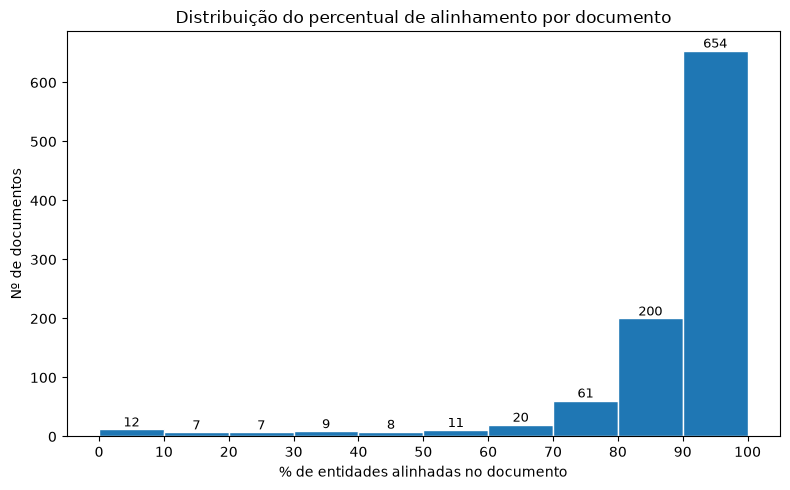

Documentos com 100% de alinhamento: 279/989
Documentos com pelo menos 1 erro: 710/989


In [ ]:
import matplotlib.pyplot as plt

# taxa de alinhamento (% de entidades OK) por documento, a partir dos JSONs já gravados em PASTA_SAIDA
taxas_alinhamento = []
for arq_gt in arquivos_gt:
    destino = PASTA_SAIDA / arq_gt.name
    if not destino.exists():
        continue
    doc = json.loads(destino.read_text(encoding="utf-8"))
    entidades = doc.get("entities", [])
    total = len(entidades)
    if total == 0:
        continue
    alinhadas = sum(1 for e in entidades if e.get("match_type") != "unmatched")
    taxas_alinhamento.append(100 * alinhadas / total)

bins = list(range(0, 101, 10))
fig, ax = plt.subplots(figsize=(8, 5))
contagens, _, patches = ax.hist(taxas_alinhamento, bins=bins, edgecolor="white")

for count, patch in zip(contagens, patches):    
    if count > 0:
        ax.text(patch.get_x() + patch.get_width() / 2, count, f"{int(count)}",
                ha="center", va="bottom", fontsize=9)

ax.set_xlabel("% de entidades alinhadas no documento")
ax.set_ylabel("Nº de documentos")
ax.set_title("Distribuição do percentual de alinhamento por documento")
ax.set_xticks(bins)
plt.tight_layout()
plt.show()

perfeitos = sum(1 for t in taxas_alinhamento if t == 100)
print(f"Documentos com 100% de alinhamento: {perfeitos}/{len(taxas_alinhamento)}")
print(f"Documentos com pelo menos 1 erro: {len(taxas_alinhamento) - perfeitos}/{len(taxas_alinhamento)}")